# 01. 모델 구조 개요 — 경량 포트홀 탐지기

**CSE36501 Deep Learning (UNIST, Fall 2026)** · 정영찬 (20221355), 조수민 (20221371)

이 노트북은 **학습을 하지 않습니다.** 모델을 설정 파일(YAML)로 *만들기만* 해서 구조와 연산량을 비교하고,
우리가 무엇을 바꾸려는지 그림으로 설명합니다. (Phase 2 학습은 별도로 진행)

| 절 | 내용 |
|---|---|
| 0 | 환경 확인 |
| 1 | 프로젝트 목표와 연구 질문 |
| 2 | 데이터 요약: 왜 "작은 포트홀"이 핵심인가 |
| 3 | 객체 탐지 모델의 해부도: Backbone · Neck · Head |
| 4 | 전이학습: 어디를 그대로 두고 어디를 바꾸나 |
| 5 | Stride와 작은 물체: P2 출력을 추가하는 이유 |
| 6 | 후보 모델 비교: 파라미터 · GFLOPs · CPU 지연시간 |
| 7 | 레이어 밖의 효율화 ①: 하늘 잘라내기 (도로 영역 입력) |
| 8 | 레이어 밖의 효율화 ②: 지식 증류 |
| 9 | 레이어 밖의 효율화 ③: FP16 / INT8 |
| 10 | 우리 설계 요약과 실험 순서 |
| 11 | 용어 정리 |


## 0. 환경 확인

- 프로젝트 루트에서 `uv pip install -r requirements.txt` 후 이 노트북을 `.venv` 커널로 실행합니다.
- 데이터(`data/processed/`)가 없으면 데이터를 쓰는 셀은 건너뜁니다. 저장된 출력(그림)은 그대로 볼 수 있습니다.

> **GPU 메모리 메모** — RTX 3070은 VRAM이 **8GB**이고, 24GB는 RTX 3090입니다. 아래 셀이 실제 값을 출력하니 확인해 주세요.
> 8GB라면 학습 시 batch 크기를 줄여야 합니다 (예: YOLO26n·640 입력 기준 16 안팎부터 시작, `batch=-1`이면 Ultralytics가 자동으로 맞춤).
> 시스템 RAM 64GB는 데이터 로딩·캐싱에 충분합니다.

**Google Colab에서 실행할 때:** GitHub에서 이 노트북을 연 뒤(파일 → 노트 열기 → GitHub),
런타임 유형을 GPU로 바꾸고 바로 아래 셀부터 실행하면 됩니다. 저장소 clone, `ultralytics` 설치,
한글 폰트(나눔고딕) 설치를 자동으로 합니다. 로컬에서는 이 셀이 아무것도 하지 않습니다.
Colab CPU는 2코어라 6절의 CPU 지연시간은 로컬 값과 다르게 나옵니다(모델 간 상대 비교로만 보세요).


In [ ]:
# Colab 전용 준비: 저장소 clone, ultralytics·한글 폰트 설치. 로컬에서는 건너뜀.
import os, subprocess, sys
from pathlib import Path

if "google.colab" in sys.modules:
    repo = Path("/content/deep-learning-cse365")
    if not repo.exists():
        subprocess.run(["git", "clone", "-q",
                        "https://github.com/queso-gato1355/deep-learning-cse365.git", str(repo)],
                       check=True)
    os.chdir(repo)  # 아래 셀은 저장소 루트를 기준으로 경로를 찾음
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.198"], check=True)
    subprocess.run("apt-get -qq install -y fonts-nanum > /dev/null", shell=True, check=True)
    from matplotlib import font_manager
    for f in Path("/usr/share/fonts/truetype/nanum").glob("*.ttf"):
        font_manager.fontManager.addfont(str(f))
    print("Colab 준비 완료:", Path.cwd())
else:
    print("로컬 실행: Colab 준비 단계 건너뜀")


In [1]:
import platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib import font_manager

warnings.filterwarnings("ignore")

# 프로젝트 루트 (notebooks/ 안에서 실행해도, 루트에서 실행해도 동작)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "processed"
HAS_DATA = (DATA / "rdd" / "index.csv").exists()

# 한글 폰트 (Windows: Malgun Gothic, macOS: AppleGothic, Linux: NanumGothic)
available = {f.name for f in font_manager.fontManager.ttflist}
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if name in available:
        plt.rcParams["font.family"] = name
        break
else:
    print("한글 폰트를 찾지 못했습니다. 그림의 한글이 깨질 수 있습니다.")
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["mathtext.fontset"] = "dejavusans"  # 로그 축의 지수·마이너스 기호용
plt.rcParams["figure.dpi"] = 110
import logging
logging.getLogger("torch.utils.flop_counter").setLevel(logging.ERROR)

print("Python   :", platform.python_version())
print("PyTorch  :", torch.__version__, "| CUDA:", torch.version.cuda)
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f"GPU      : {p.name} | VRAM {p.total_memory / 2**30:.1f} GB")
else:
    print("GPU      : 없음 (CPU 모드)")
print("데이터    :", "있음" if HAS_DATA else "없음 → 데이터 셀은 건너뜀")


Python   : 3.11.17
PyTorch  : 2.11.0+cu128 | CUDA: 12.8
GPU      : NVIDIA GeForce RTX 3090 | VRAM 24.0 GB
데이터    : 있음


## 1. 프로젝트 목표와 연구 질문

**문제 상황.** 지금은 도로공사 직원의 점검이나 시민 신고로 포트홀 위치를 파악합니다.
작은 포트홀은 거의 신고되지 않고, 교외 도로의 포트홀은 신고가 늦습니다.

**아이디어.** 자율주행차가 보편화되면 모든 차가 도로를 보고 있으므로, 차가 포트홀을 감지해 위치를 **자동으로 신고**할 수 있습니다.

**제약.** 차량의 연산 자원은 주행에 써야 합니다. 포트홀 감지는 *부가 작업*이므로 **효율적이고, 빠르고, 연산량이 적어야** 합니다.

| | 연구 질문 |
|---|---|
| **RQ1** | 포트홀 탐지기를 얼마나 작고 빠르게 만들어도 쓸 만한 정확도를 유지하는가? (정확도–효율 트레이드오프) |
| **RQ2** | 어떤 효율화 수단이 정확도를 가장 적게 잃는가? — 더 작은 모델 / 낮은 입력 해상도 / 경량 모듈 설계 / 낮은 정밀도 |
| **RQ3** | 효율적인 모델이 차가 실제로 만날 조건(다른 나라·카메라, 비)에서도 믿을 만한가? |

모든 결과는 **정확도**(mAP50, mAP50-95, recall, 작은 물체 AP)와 **비용**(파라미터 수, GFLOPs, GPU/CPU FPS)을 **함께** 보고합니다.


## 2. 데이터 요약: 왜 "작은 포트홀"이 핵심인가

- **RDD2022**: 6개국 차량 카메라 영상. 손상 4종 중 `D40`(포트홀)만 사용 → 학습/검증/테스트(A).
- **MWPD**: 다른 출처 + 실제 비. 테스트 전용(C: 맑음, D: 비). B1–B3는 A에 합성 비를 씌운 것.

아래 표와 그림은 Phase 1에서 자동 생성된 것입니다 (`outputs/tables`, `outputs/figures`).


,Dataset,Split,Images,Boxes,Neg. images,Mean box area (%),Resolution
0,RDD2022,train,3160,4497,630,1.53,512x512 – 4040x2044
1,RDD2022,val,638,915,126,1.53,512x512 – 4040x2044
2,RDD2022,test (A),708,1046,140,1.54,512x512 – 4040x2044
3,MWPD,normal (C),681,1450,0,8.31,640x640 – 640x640
4,MWPD,rainy (D_full),676,2658,0,6.93,640x640 – 640x640
5,MWPD,rainy_train (S3),340,1270,0,7.79,640x640 – 640x640
6,MWPD,"rainy (D_half, S3)",336,1388,0,6.14,640x640 – 640x640


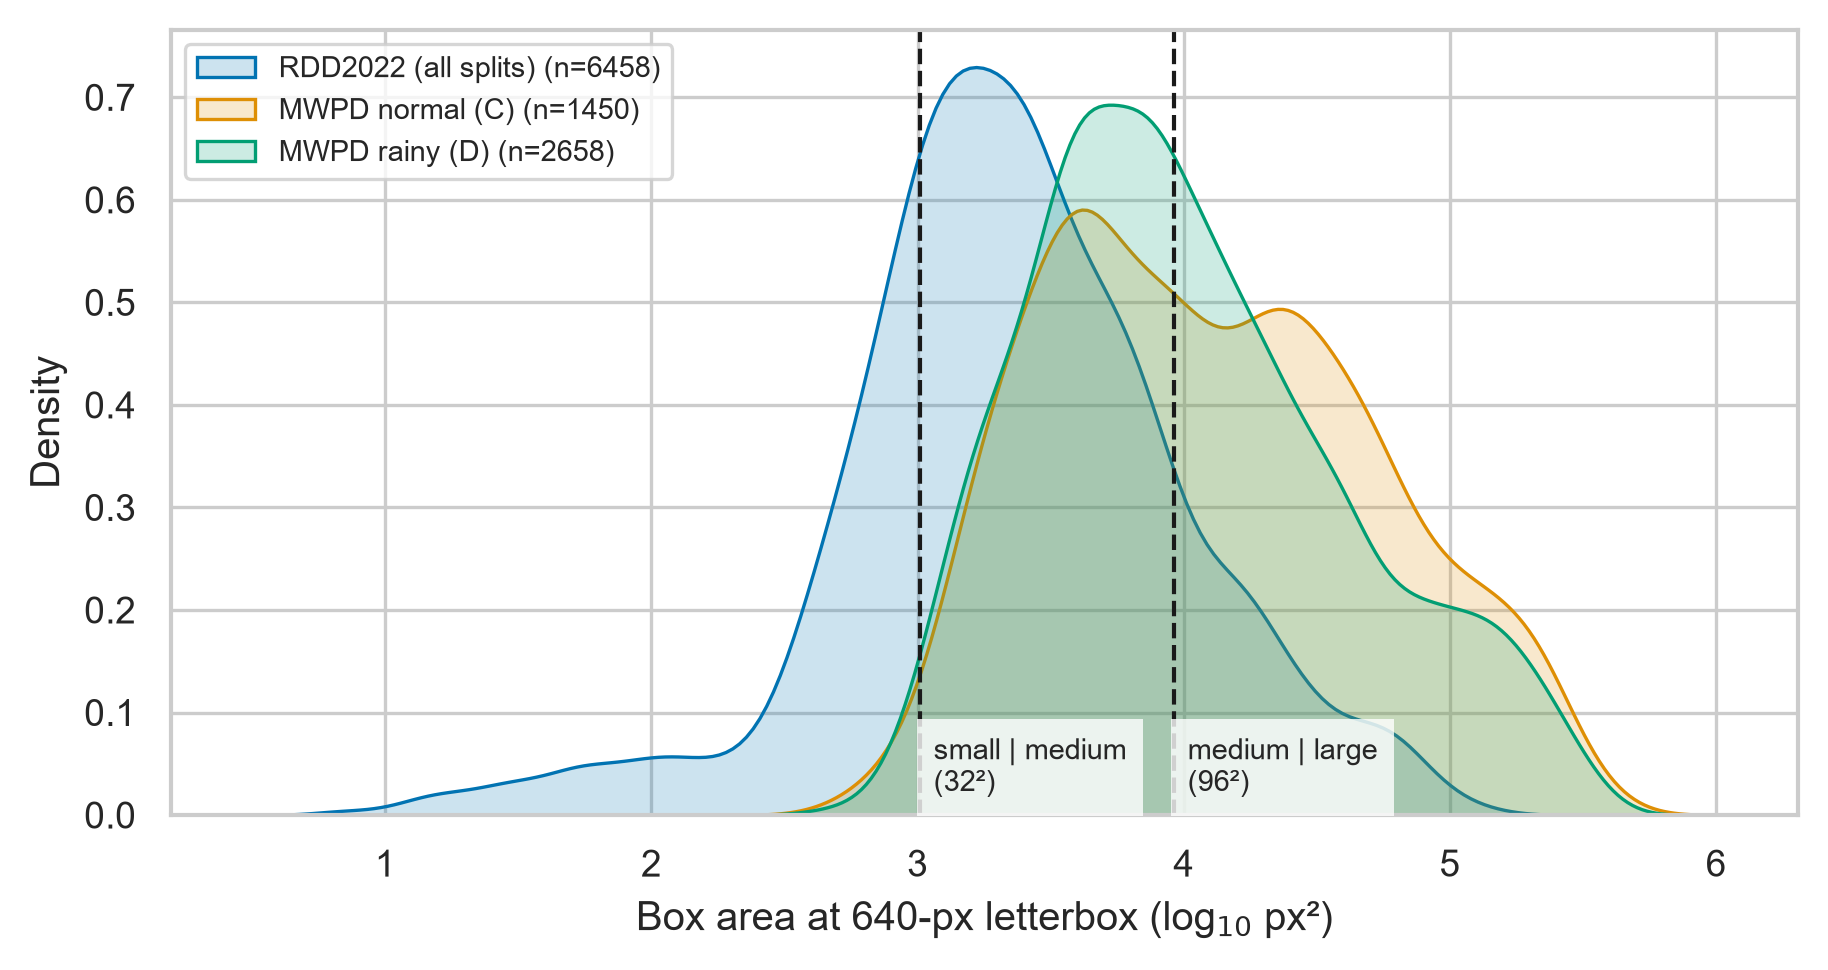

In [2]:
from IPython.display import Image, display

summary = pd.read_csv(ROOT / "outputs" / "tables" / "tab_dataset_summary.csv")
display(summary)
display(Image(filename=str(ROOT / "outputs" / "figures" / "fig_box_size.png"), width=700))


**읽는 법.** 가로축은 640px 입력 기준 박스 넓이(로그)입니다. 점선 왼쪽(32² 미만)이 COCO 기준 **small** 물체입니다.

- RDD 포트홀의 약 **26%가 small** → 멀리 있는 작은 포트홀이 많습니다.
- 그런데 **사람들이 신고하지 않는 것이 바로 작은 포트홀**이고,
  모델을 작게 만들거나 입력 해상도를 낮추면 **가장 먼저 놓치는 것도 작은 포트홀**입니다.
- 그래서 이 프로젝트는 효율화를 하면서도 **작은 물체 AP를 따로 지켜보는 것**이 핵심입니다.


## 3. 객체 탐지 모델의 해부도: Backbone · Neck · Head

YOLO 계열 탐지기는 세 부분으로 나뉩니다.

| 부분 | 하는 일 | 비유 |
|---|---|---|
| **Backbone** | 이미지에서 특징(feature)을 뽑음. 뒤로 갈수록 해상도는 작아지고 의미는 추상적 | "눈" |
| **Neck** | 서로 다른 해상도의 특징을 위·아래로 섞음 (FPN/PAN) | "정리" |
| **Head** | 각 해상도에서 "어디에 박스가 있고, 포트홀인가"를 출력 | "판단" |

**P2~P5**는 특징 맵의 단계 이름입니다. `P3/8`은 원본을 **8배 축소**한 맵(640 입력이면 80×80)이라는 뜻입니다.
기본 YOLO는 P3·P4·P5 세 곳에서 출력합니다.


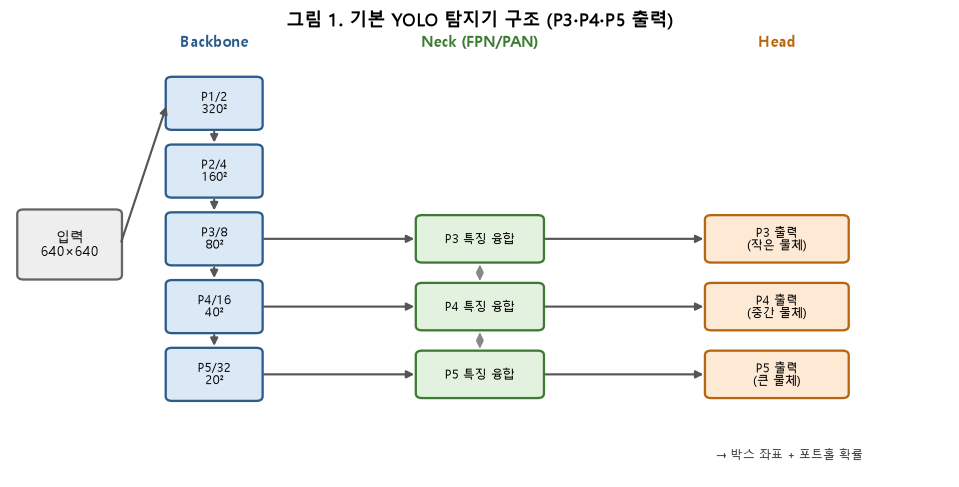

In [3]:
def box(ax, x, y, w, h, text, fc="#dbe9f6", ec="#2b5c8a", fs=9, bold=False):
    ax.add_patch(mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                         fc=fc, ec=ec, lw=1.5))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs,
            fontweight="bold" if bold else "normal")

def arrow(ax, x0, y0, x1, y1, color="#555", style="-|>", lw=1.4, ls="-"):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle=style, color=color, lw=lw, linestyle=ls))

def draw_detector(ax, title, colors=None, with_p2=False):
    # colors: dict(part -> (fc, ec)) to recolor backbone/neck/head/new parts
    c = {"backbone": ("#dbe9f6", "#2b5c8a"), "neck": ("#e3f1df", "#3d7a33"),
         "head": ("#fde9d4", "#b8650f"), "new": ("#fbd5d5", "#b22222")}
    if colors:
        c.update(colors)
    ax.set_xlim(0, 12); ax.set_ylim(-0.6, 7.2); ax.axis("off")
    ax.set_title(title, fontsize=12, fontweight="bold")
    box(ax, 0.1, 2.9, 1.3, 1.2, "입력\n640×640", fc="#eeeeee", ec="#666")
    stages = [("P1/2\n320²", 6.0), ("P2/4\n160²", 4.8), ("P3/8\n80²", 3.6),
              ("P4/16\n40²", 2.4), ("P5/32\n20²", 1.2)]
    ax.text(2.6, 7.0, "Backbone", ha="center", fontsize=10, fontweight="bold", color=c["backbone"][1])
    for name, y in stages:
        box(ax, 2.0, y - 0.45, 1.2, 0.9, name, *c["backbone"], fs=8)
    for (_, y0), (_, y1) in zip(stages[:-1], stages[1:]):
        arrow(ax, 2.6, y0 - 0.45, 2.6, y1 + 0.45)
    arrow(ax, 1.4, 3.5, 2.0, 6.0)
    ax.text(6.0, 7.0, "Neck (FPN/PAN)", ha="center", fontsize=10, fontweight="bold", color=c["neck"][1])
    ax.text(9.8, 7.0, "Head", ha="center", fontsize=10, fontweight="bold", color=c["head"][1])
    levels = [("P3", 3.6, "작은 물체"), ("P4", 2.4, "중간 물체"), ("P5", 1.2, "큰 물체")]
    if with_p2:
        levels = [("P2", 4.8, "아주 작은 물체")] + levels
    for name, y, desc in levels:
        new = with_p2 and name == "P2"
        fc, ec = c["new"] if new else c["neck"]
        box(ax, 5.2, y - 0.4, 1.6, 0.8, f"{name} 특징 융합", fc, ec, fs=8)
        arrow(ax, 3.2, y, 5.2, y, color=ec if new else "#555")
        fc, ec = c["new"] if new else c["head"]
        box(ax, 8.9, y - 0.4, 1.8, 0.8, f"{name} 출력\n({desc})", fc, ec, fs=8)
        arrow(ax, 6.8, y, 8.9, y, color=ec if new else "#555")
    ys = [y for _, y, _ in levels]
    for y0, y1 in zip(ys[:-1], ys[1:]):  # top-down and bottom-up mixing inside the neck
        arrow(ax, 6.0, y0 - 0.4, 6.0, y1 + 0.4, color="#888", style="<|-|>", lw=1)
    ax.text(10.9, -0.3, "→ 박스 좌표 + 포트홀 확률", ha="right", fontsize=8, color="#444")

fig, ax = plt.subplots(figsize=(11, 5.2))
draw_detector(ax, "그림 1. 기본 YOLO 탐지기 구조 (P3·P4·P5 출력)")
plt.show()


## 4. 전이학습: 어디를 그대로 두고 어디를 바꾸나

교수님이 말씀하신 "**상위 몇 개 레이어를 바꾸는 과정**"이 바로 **전이학습(transfer learning)/미세조정(fine-tuning)** 입니다.

1. COCO(80종, 약 11.8만 장)로 미리 학습된 가중치를 가져옵니다.
2. **아래쪽(backbone)은 그대로**: 선·색·질감 같은 일반적 특징은 어떤 이미지든 비슷합니다.
3. **맨 위 출력층은 교체**: 80종 → 1종(포트홀).
4. 우리 데이터(RDD 학습 이미지 약 3,160장)로 다시 학습합니다. 데이터가 적어서 이 방식이 사실상 필수입니다.

우리 설계는 여기에 **P2 가지를 추가**합니다(5절). 새로 추가한 층과 교체한 출력층만 무작위로 시작하고,
나머지는 이름·모양이 맞는 사전학습 가중치를 불러옵니다. 필요하면 처음 몇 epoch 동안 backbone 앞부분을 **고정(freeze)** 합니다.


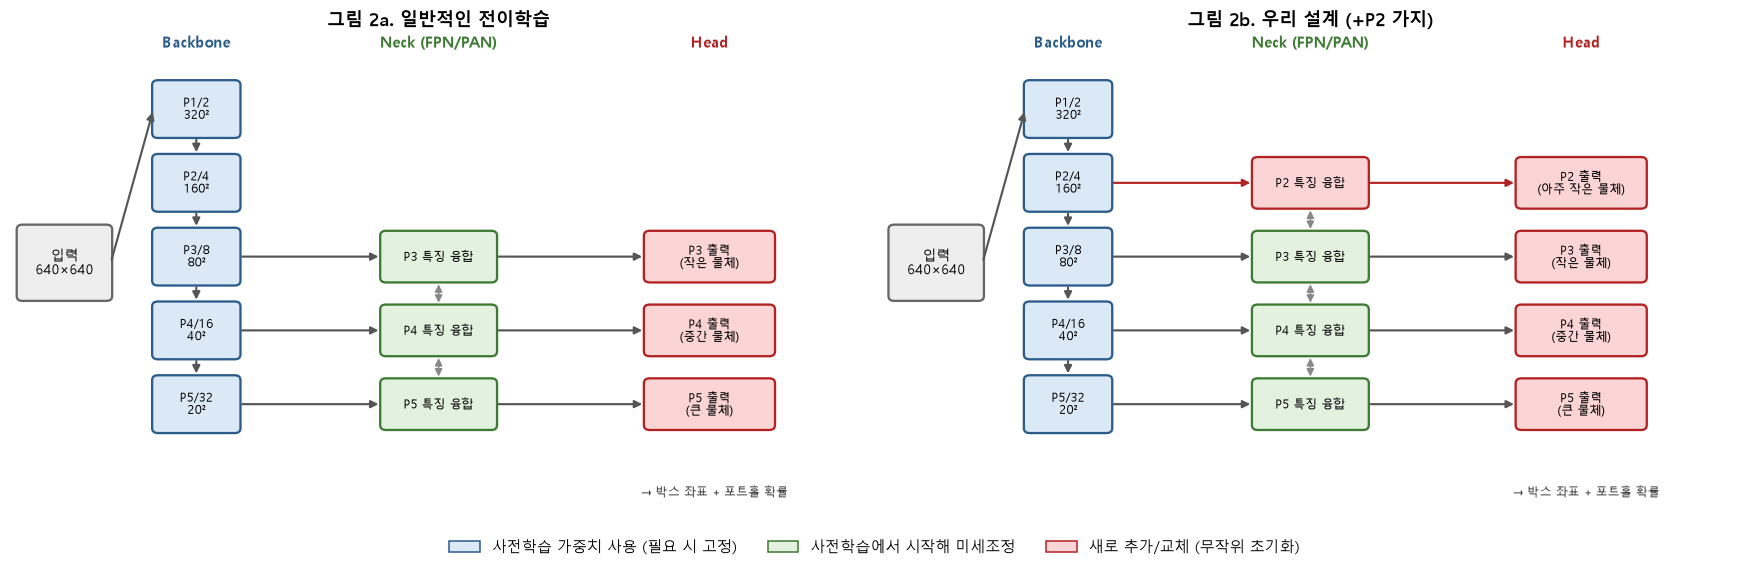

In [4]:
pre = ("#dbe9f6", "#2b5c8a")     # 사전학습 가중치 그대로
tuned = ("#e3f1df", "#3d7a33")   # 사전학습 가중치에서 시작해 미세조정
newc = ("#fbd5d5", "#b22222")    # 새로 만듦 (무작위 초기화)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
draw_detector(axes[0], "그림 2a. 일반적인 전이학습", {"backbone": pre, "neck": tuned, "head": newc})
draw_detector(axes[1], "그림 2b. 우리 설계 (+P2 가지)", {"backbone": pre, "neck": tuned, "head": newc,
                                                         "new": newc}, with_p2=True)
handles = [mpatches.Patch(fc=pre[0], ec=pre[1], label="사전학습 가중치 사용 (필요 시 고정)"),
           mpatches.Patch(fc=tuned[0], ec=tuned[1], label="사전학습에서 시작해 미세조정"),
           mpatches.Patch(fc=newc[0], ec=newc[1], label="새로 추가/교체 (무작위 초기화)")]
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=10, frameon=False)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()


## 5. Stride와 작은 물체: P2 출력을 추가하는 이유

출력 단계의 **stride**만큼 이미지가 격자로 나뉘고, 각 칸(cell)이 "여기에 물체가 있나"를 판단합니다.
작은 포트홀이 굵은 격자(stride 32)에서는 **한 칸의 일부**밖에 안 되어 특징이 다른 배경과 섞여 버립니다.

아래 그림은 RDD 테스트셋의 **실제 작은 포트홀**에 stride별 격자를 겹친 것입니다.
기본 YOLO의 가장 촘촘한 출력은 stride 8(P3)이고, **P2를 추가하면 stride 4** 격자가 생깁니다.


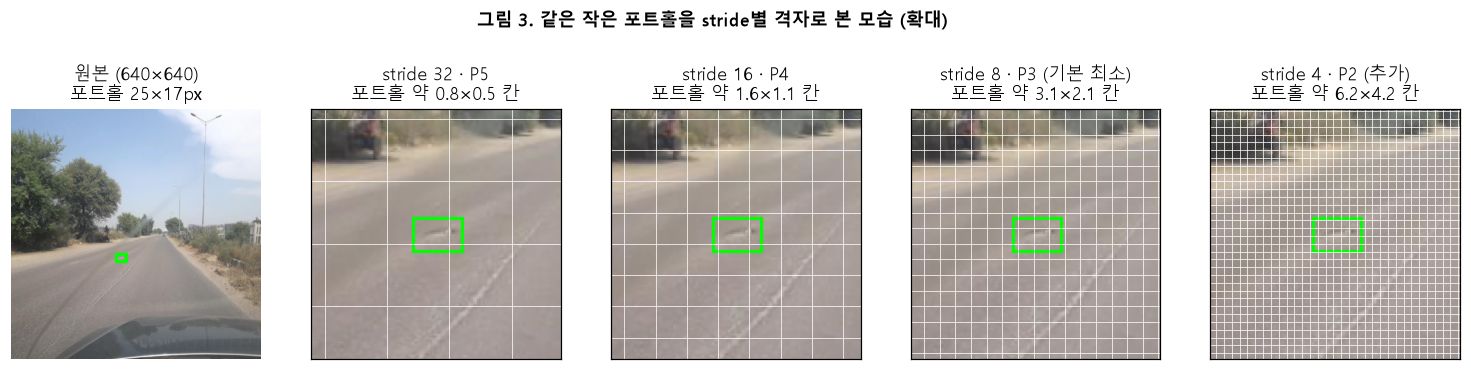

In [5]:
import cv2

def imread(path):
    return cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)  # 한글 경로 대응

if HAS_DATA:
    idx = pd.read_csv(DATA / "rdd" / "index.csv").set_index("stem")
    cand = []
    for ln in (DATA / "splits" / "rdd_test.txt").read_text().split():
        stem = Path(ln).stem
        W, H = idx.loc[stem, ["width", "height"]]
        s = 640 / max(W, H)
        for r in (DATA / "rdd" / "labels" / f"{stem}.txt").read_text().splitlines():
            _, cx, cy, w, h = map(float, r.split())
            area = w * W * s * h * H * s
            if 150 < area < 500 and W == H:  # 정사각 이미지의 작은 포트홀
                cand.append((area, stem, cx, cy, w, h))
    EXAMPLE = "India_005660"  # 탁 트인 도로 위 멀리 있는 작은 포트홀 (사람이 골라 둔 예시)
    pick = [c for c in cand if c[1] == EXAMPLE] or [sorted(cand)[len(cand) // 2]]
    area, stem, cx, cy, w, h = pick[0]
    img = cv2.cvtColor(cv2.resize(imread(DATA / "rdd" / "images" / f"{stem}.jpg"), (640, 640)),
                       cv2.COLOR_BGR2RGB)
    bx, by, bw, bh = (cx - w / 2) * 640, (cy - h / 2) * 640, w * 640, h * 640
    fig, axes = plt.subplots(1, 5, figsize=(17, 3.8))
    axes[0].imshow(img); axes[0].add_patch(mpatches.Rectangle((bx, by), bw, bh, fill=False, ec="lime", lw=2))
    axes[0].set_title(f"원본 (640×640)\n포트홀 {bw:.0f}×{bh:.0f}px"); axes[0].axis("off")
    win = 128
    x0 = int(np.clip(cx * 640 - win / 2, 0, 640 - win)); y0 = int(np.clip(cy * 640 - win / 2, 0, 640 - win))
    for ax, s in zip(axes[1:], [32, 16, 8, 4]):
        ax.imshow(img[y0:y0 + win, x0:x0 + win], extent=(x0, x0 + win, y0 + win, y0))
        for g in range(0, 641, s):
            ax.axvline(g, color="white", lw=0.6, alpha=0.8); ax.axhline(g, color="white", lw=0.6, alpha=0.8)
        ax.add_patch(mpatches.Rectangle((bx, by), bw, bh, fill=False, ec="lime", lw=2))
        ax.set_xlim(x0, x0 + win); ax.set_ylim(y0 + win, y0); ax.set_xticks([]); ax.set_yticks([])
        tag = {32: "P5", 16: "P4", 8: "P3 (기본 최소)", 4: "P2 (추가)"}[s]
        ax.set_title(f"stride {s} · {tag}\n포트홀 약 {bw / s:.1f}×{bh / s:.1f} 칸")
    fig.suptitle("그림 3. 같은 작은 포트홀을 stride별 격자로 본 모습 (확대)", fontweight="bold", y=1.03)
    plt.show()
else:
    print("데이터가 없어 건너뜁니다.")


**해석.** stride 8에서도 포트홀이 1~2칸 정도뿐이지만, stride 4에서는 여러 칸에 걸쳐 모양 정보가 남습니다.
그래서 작은 포트홀용으로 **P2 출력 가지를 추가**합니다. 대신 P2는 160×160 맵이라 연산이 늘어납니다 → 다음 절에서 숫자로 확인합니다.


## 6. 후보 모델 비교: 파라미터 · GFLOPs · CPU 지연시간

설정 파일(YAML)에서 **1클래스(포트홀)** 모델을 만들어 비교합니다 (가중치 다운로드 없음, 학습 없음).

- **YOLOv8n/s**: 널리 쓰이는 기준 모델.
- **YOLO26n/s**: Ultralytics 최신 계열. **NMS(중복 박스 제거 후처리)가 필요 없는 end-to-end 구조**.
- **YOLO26n-P2**: 라이브러리에 포함된 P2 출력 버전 (`yolo26-p2.yaml`).

GFLOPs는 PyTorch 내장 `FlopCounterMode`로 셉니다 (곱셈·덧셈 각각 1 FLOP).
`384×640`은 7절의 "하늘 잘라내기"를 적용한 입력 크기입니다. CPU 지연시간은 이 PC 기준의 참고값입니다.


In [6]:
import time
from torch.utils.flop_counter import FlopCounterMode
from ultralytics.nn.tasks import DetectionModel
from ultralytics.utils import LOGGER
LOGGER.setLevel("ERROR")

def gflops(model, hw):
    with FlopCounterMode(display=False) as fc, torch.no_grad():
        model(torch.zeros(1, 3, *hw))
    return fc.get_total_flops() / 1e9

def cpu_ms(model, hw, n=20):
    x = torch.zeros(1, 3, *hw)
    with torch.no_grad():
        for _ in range(5):
            model(x)
        t = time.perf_counter()
        for _ in range(n):
            model(x)
    return (time.perf_counter() - t) / n * 1000

torch.set_num_threads(4)  # 차량용 CPU를 흉내 내기 위해 스레드 4개로 제한 (참고용)
rows = []
for name, cfg in [("YOLOv8n", "yolov8n.yaml"), ("YOLOv8s", "yolov8s.yaml"), ("YOLO26n", "yolo26n.yaml"),
                  ("YOLO26s", "yolo26s.yaml"), ("YOLO26n-P2", "yolo26n-p2.yaml")]:
    m = DetectionModel(cfg, nc=1, verbose=False).eval()
    rows.append({"모델": name,
                 "파라미터(M)": sum(p.numel() for p in m.parameters()) / 1e6,
                 "GFLOPs @640×640": gflops(m, (640, 640)),
                 "GFLOPs @384×640": gflops(m, (384, 640)),
                 "CPU ms @640 (4스레드)": cpu_ms(m, (640, 640)),
                 "CPU ms @384×640": cpu_ms(m, (384, 640))})
models = pd.DataFrame(rows).set_index("모델").round(2)
models


,파라미터(M),GFLOPs @640×640,GFLOPs @384×640,CPU ms @640 (4스레드),CPU ms @384×640
모델,,,,,
YOLOv8n,3.01,8.08,4.85,27.41,19.04
YOLOv8s,11.14,28.43,17.06,71.21,44.45
YOLO26n,2.50,5.74,3.41,34.27,23.82
YOLO26s,9.95,22.44,13.40,75.81,49.92
YOLO26n-P2,2.52,7.37,4.39,49.56,35.54


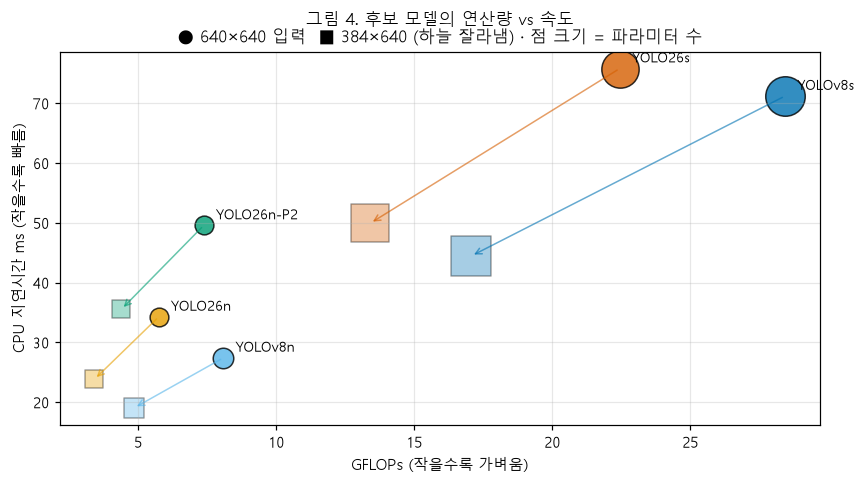

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = {"YOLOv8n": "#56B4E9", "YOLOv8s": "#0072B2", "YOLO26n": "#E69F00", "YOLO26s": "#D55E00",
          "YOLO26n-P2": "#009E73"}
for name, r in models.iterrows():
    ax.scatter(r["GFLOPs @640×640"], r["CPU ms @640 (4스레드)"], s=r["파라미터(M)"] * 60,
               color=colors[name], alpha=0.8, edgecolor="k")
    ax.annotate(name, (r["GFLOPs @640×640"], r["CPU ms @640 (4스레드)"]), xytext=(8, 4),
                textcoords="offset points", fontsize=9)
    ax.scatter(r["GFLOPs @384×640"], r["CPU ms @384×640"], s=r["파라미터(M)"] * 60, color=colors[name],
               alpha=0.35, marker="s", edgecolor="k")
    ax.annotate("", xy=(r["GFLOPs @384×640"], r["CPU ms @384×640"]),
                xytext=(r["GFLOPs @640×640"], r["CPU ms @640 (4스레드)"]),
                arrowprops=dict(arrowstyle="->", color=colors[name], alpha=0.6))
ax.set_xlabel("GFLOPs (작을수록 가벼움)"); ax.set_ylabel("CPU 지연시간 ms (작을수록 빠름)")
ax.set_title("그림 4. 후보 모델의 연산량 vs 속도\n● 640×640 입력  ■ 384×640 (하늘 잘라냄) · 점 크기 = 파라미터 수",
             fontsize=11)
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()


**포인트.**
- 같은 n 크기에서 **YOLO26n이 YOLOv8n보다 가볍습니다** (파라미터·GFLOPs 모두).
- **그런데 CPU 지연시간은 YOLO26n이 더 깁니다.** → *GFLOPs가 적다고 항상 빠른 것은 아닙니다.*
  층의 종류(메모리 접근이 많은 연산 등)와 실행 환경에 따라 실제 속도가 달라집니다.
  또 여기 측정은 PyTorch 기본 실행 + 모델 본체만이라, YOLO26의 장점인 **NMS 생략 효과가 빠져 있습니다.**
  그래서 Phase 2에서는 **ONNX/TensorRT로 변환한 뒤, 후처리까지 포함한 전체 시간**을 따로 잽니다.
- **P2를 추가하면 GFLOPs가 늘지만**, 하늘을 잘라낸 384×640 입력과 함께 쓰면 **원래 YOLO26n(640×640)보다도 가벼워집니다.**
- 정확도는 아직 모릅니다 → Phase 2에서 학습 후 이 그림의 세로축을 **mAP**로 바꾼 "정확도–비용 곡선"이 핵심 결과가 됩니다.


## 7. 레이어 밖의 효율화 ①: 하늘 잘라내기 (도로 영역 입력)

차량 카메라에서 포트홀은 **도로 위**, 즉 화면 아래쪽에만 나타납니다. 위쪽 하늘·건물은 연산 낭비입니다.
입력을 640×640 → **384×640(아래 60%)** 로 바꾸면 모든 층의 연산이 약 40% 줄고, **포트홀 크기는 줄지 않습니다.**
(해상도를 낮추는 것과의 차이: 해상도를 낮추면 포트홀도 같이 작아집니다.)

**공짜는 아닙니다.** 실제 RDD 라벨로 "잘라낸 영역 밖으로 나가는 포트홀"이 얼마나 되는지 확인합니다.


,남기는 아래쪽 비율,완전히 포함되는 포트홀 %
0,0.5,89.9
1,0.6,92.9
2,0.7,95.4


,아래 60%에 완전히 포함 (%)
country,
China_MotorBike,46.6
Czech,100.0
India,98.7
Japan,87.2
Norway,100.0
United_States,100.0


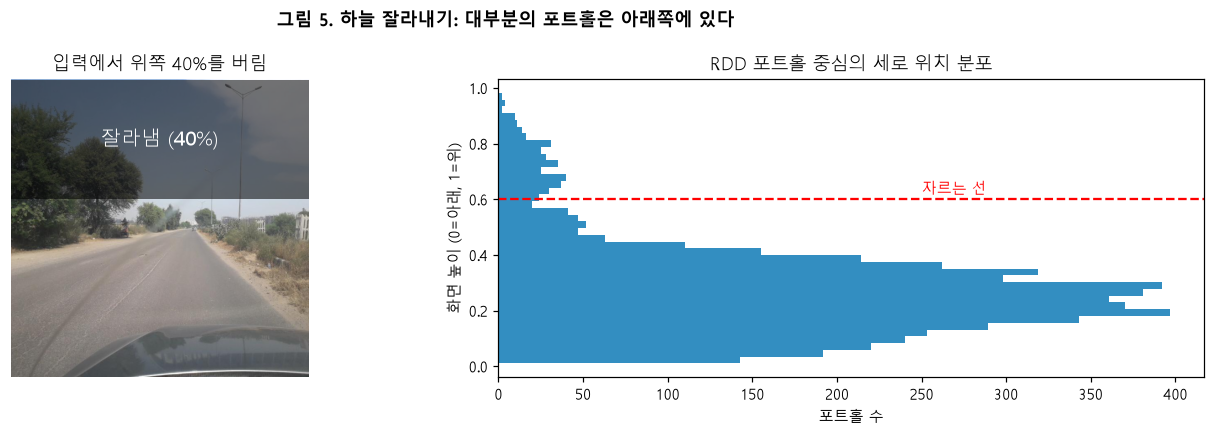

In [8]:
if HAS_DATA:
    idx = pd.read_csv(DATA / "rdd" / "index.csv").set_index("stem")
    rows = []
    for split in ["rdd_train", "rdd_test"]:
        for ln in (DATA / "splits" / f"{split}.txt").read_text().split():
            stem = Path(ln).stem
            for r in (DATA / "rdd" / "labels" / f"{stem}.txt").read_text().splitlines():
                _, cx, cy, w, h = map(float, r.split())
                rows.append({"country": idx.loc[stem, "country"], "cy": cy, "top": cy - h / 2})
    b = pd.DataFrame(rows)
    keep = pd.DataFrame({"남기는 아래쪽 비율": [0.5, 0.6, 0.7]})
    keep["완전히 포함되는 포트홀 %"] = [100 * (b.top >= 1 - k).mean() for k in keep["남기는 아래쪽 비율"]]
    display(keep.round(1))
    per_country = (b.assign(inside=b.top >= 0.4).groupby("country")["inside"].mean() * 100).round(1)
    display(per_country.rename("아래 60%에 완전히 포함 (%)").to_frame())

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    stem = "India_005660"  # 5절과 같은 예시 이미지
    img = cv2.cvtColor(imread(DATA / "rdd" / "images" / f"{stem}.jpg"), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    axes[0].imshow(img); axes[0].add_patch(mpatches.Rectangle((0, 0), W, 0.4 * H, fc="black", alpha=0.55))
    axes[0].text(W / 2, 0.2 * H, "잘라냄 (40%)", color="white", ha="center", va="center", fontsize=13)
    axes[0].set_title("입력에서 위쪽 40%를 버림"); axes[0].axis("off")
    axes[1].hist(1 - b.cy, bins=40, color="#0072B2", alpha=0.8, orientation="horizontal")
    axes[1].axhline(0.6, color="red", ls="--"); axes[1].text(axes[1].get_xlim()[1] * 0.6, 0.62, "자르는 선", color="red")
    axes[1].set_ylabel("화면 높이 (0=아래, 1=위)"); axes[1].set_xlabel("포트홀 수")
    axes[1].set_title("RDD 포트홀 중심의 세로 위치 분포")
    fig.suptitle("그림 5. 하늘 잘라내기: 대부분의 포트홀은 아래쪽에 있다", fontweight="bold")
    plt.tight_layout(); plt.show()
else:
    print("데이터가 없어 건너뜁니다.")


**해석 (Phase 1 데이터 기준).**
- 아래 60%만 남기면 RDD 포트홀의 **약 93%** 가 완전히 포함됩니다 → 연산 약 40% 절감 vs 포트홀 약 7% 손실.
- 나라별 차이가 큽니다: Norway·Czech·US는 100%, India 99%, **Japan 87%**, **China_MotorBike 47%** (오토바이 카메라는 시점이 달라 화면 위쪽까지 도로가 보임).
- 즉 **잘라낼 비율은 카메라 장착 위치에 따라 정해야 하는 값**이고, 실험에서 50/60/70%를 비교할 가치가 있습니다.
- MWPD(C/D)는 근접 사진이 많아 자르기를 그대로 적용하기 어렵습니다 → 견고성 평가에서는 전체 이미지 입력도 함께 봅니다.


## 8. 레이어 밖의 효율화 ②: 지식 증류 (Knowledge Distillation)

큰 모델(**교사**, 예: YOLOv8s 또는 RT-DETR)을 먼저 학습한 뒤, 작은 모델(**학생**, 예: YOLO26n-P2)이
정답 라벨뿐 아니라 **교사의 출력(또는 중간 특징)도 따라 하도록** 학습합니다.

- 추론할 때는 **학생만** 씁니다 → 실행 비용 0, 학습 시간만 늘어남.
- 학습 이미지가 약 3,160장으로 적어서, 교사의 "부드러운 정답"이 추가 정보를 줍니다.


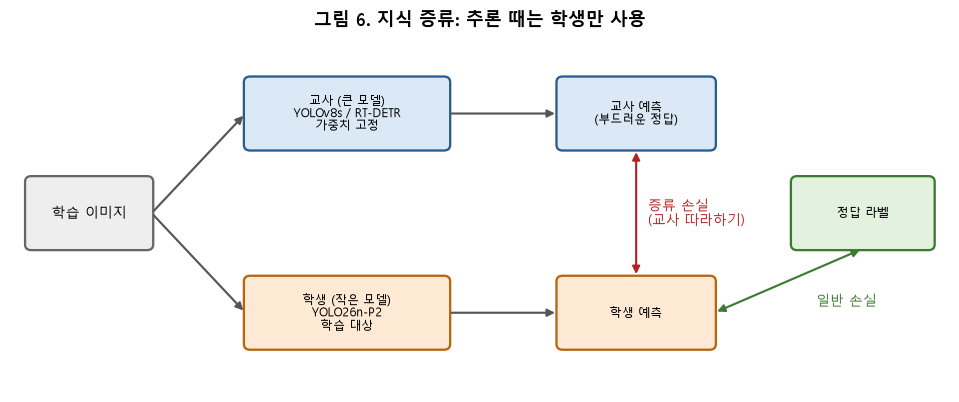

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.set_xlim(0, 12); ax.set_ylim(0, 5); ax.axis("off")
box(ax, 0.2, 2.0, 1.6, 1.0, "학습 이미지", fc="#eeeeee", ec="#666")
box(ax, 3.0, 3.4, 2.6, 1.0, "교사 (큰 모델)\nYOLOv8s / RT-DETR\n가중치 고정", fc="#dbe9f6", ec="#2b5c8a", fs=8)
box(ax, 3.0, 0.6, 2.6, 1.0, "학생 (작은 모델)\nYOLO26n-P2\n학습 대상", fc="#fde9d4", ec="#b8650f", fs=8)
box(ax, 7.0, 3.4, 2.0, 1.0, "교사 예측\n(부드러운 정답)", fc="#dbe9f6", ec="#2b5c8a", fs=8)
box(ax, 7.0, 0.6, 2.0, 1.0, "학생 예측", fc="#fde9d4", ec="#b8650f", fs=8)
box(ax, 10.0, 2.0, 1.8, 1.0, "정답 라벨", fc="#e3f1df", ec="#3d7a33", fs=8)
for y in (3.9, 1.1):
    arrow(ax, 1.8, 2.5, 3.0, y)
arrow(ax, 5.6, 3.9, 7.0, 3.9); arrow(ax, 5.6, 1.1, 7.0, 1.1)
arrow(ax, 8.0, 3.4, 8.0, 1.6, color="#b22222", style="<|-|>")
ax.text(8.15, 2.5, "증류 손실\n(교사 따라하기)", color="#b22222", fontsize=9, va="center")
arrow(ax, 10.9, 2.0, 9.0, 1.1, color="#3d7a33", style="<|-|>")
ax.text(10.3, 1.2, "일반 손실", color="#3d7a33", fontsize=9)
ax.set_title("그림 6. 지식 증류: 추론 때는 학생만 사용", fontweight="bold")
plt.show()


## 9. 레이어 밖의 효율화 ③: FP16 / INT8 (낮은 정밀도)

학습이 끝난 가중치는 보통 32비트 실수(FP32)입니다. 이를 **16비트(FP16)** 나 **8비트 정수(INT8)** 로 바꾸면
메모리와 연산이 줄고, 차량용 칩(NPU/GPU)에서 훨씬 빨라집니다. 대신 **반올림 오차**가 생깁니다.

아래는 실제 모델의 한 conv 층 가중치를 FP16·INT8로 바꿨을 때의 오차를 보여주는 **예시**입니다
(학습 전 무작위 초기화 가중치라 분포가 평평합니다. 값 자체보다 "INT8은 256단계로 뭉뚱그린다"는 개념을 보는 용도).
INT8은 정확도가 떨어질 수 있어, 실험에서는 **변환 전후 mAP 차이**를 직접 측정합니다.


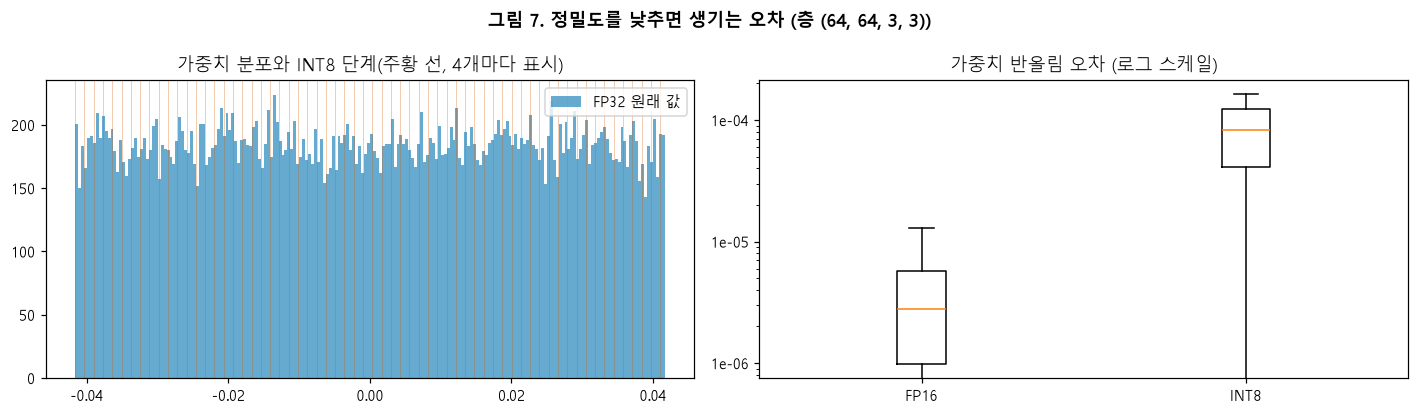

평균 절대 오차  FP16: 3.83e-06   INT8: 8.20e-05
메모리: FP32 4바이트 → FP16 2바이트 → INT8 1바이트 (가중치 기준 1/4)


In [10]:
m = DetectionModel("yolo26n.yaml", nc=1, verbose=False)
conv = next(mod for mod in m.modules() if isinstance(mod, torch.nn.Conv2d) and mod.weight.numel() > 5000)
w = conv.weight.detach().flatten()
w16 = w.half().float()
scale = w.abs().max() / 127                      # 대칭 per-tensor INT8
w8 = torch.clamp(torch.round(w / scale), -127, 127) * scale

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(w.numpy(), bins=200, color="#0072B2", alpha=0.6, label="FP32 원래 값")
for lv in torch.unique(w8).numpy()[::4]:
    axes[0].axvline(lv, color="#D55E00", lw=0.4, alpha=0.5)
axes[0].set_title("가중치 분포와 INT8 단계(주황 선, 4개마다 표시)"); axes[0].legend()
err = pd.DataFrame({"FP16": (w16 - w).abs().numpy(), "INT8": (w8 - w).abs().numpy()})
axes[1].boxplot([err["FP16"], err["INT8"]], tick_labels=["FP16", "INT8"], showfliers=False)
axes[1].set_yscale("log")
axes[1].yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:.0e}"))  # 한글 폰트엔 수학 마이너스 기호가 없음
axes[1].set_title("가중치 반올림 오차 (로그 스케일)")
fig.suptitle(f"그림 7. 정밀도를 낮추면 생기는 오차 (층 {tuple(conv.weight.shape)})", fontweight="bold")
plt.tight_layout(); plt.show()
print(f"평균 절대 오차  FP16: {err.FP16.mean():.2e}   INT8: {err.INT8.mean():.2e}")
print("메모리: FP32 4바이트 → FP16 2바이트 → INT8 1바이트 (가중치 기준 1/4)")


## 10. 우리 설계 요약과 실험 순서

**기본 틀**: COCO 사전학습 backbone + 포트홀 1클래스 head (표준 전이학습)
**+ 구조 변경 (레이어 안)**: P2 출력 가지 추가 → 작은 포트홀
**+ 구조 밖 효율화**: 하늘 잘라내기(입력) · 지식 증류(학습) · FP16/INT8(배포)

> 보고서용 한 줄 요약: *We follow standard transfer learning (COCO-pretrained backbone, task-specific head) and add
> (a) an architectural change — a high-resolution P2 detection branch for small potholes — and
> (b) non-architectural efficiency levers — road-region cropping, knowledge distillation and reduced precision.*

**실험 사다리 (계획, Phase 2에서 확정)** — 한 번에 하나씩 바꿔서 무엇이 효과인지 분리합니다 (= RQ2).

| 단계 | 바꾸는 것 | 보는 것 |
|---|---|---|
| 1 | YOLOv8n vs YOLO26n (+ s 크기, RT-DETR-L은 정확도 상한 참고) | 같은 크기에서 계열 차이 |
| 2 | 입력 해상도 640 → 480 → 320 | 작은 포트홀 AP가 언제 무너지나 |
| 3 | 하늘 잘라내기 (아래 50/60/70%) | 연산 절감 vs 놓치는 포트홀 |
| 4 | + P2 가지 | 작은 물체 AP 회복 vs 연산 증가 |
| 5 | + 지식 증류 | 실행 비용 0으로 정확도 회복 |
| 6 | FP16 / INT8 변환 | 속도 향상 vs mAP 손실 |
| 평가 | 각 단계를 A(주 정확도) + B/C/D(견고성)에서 | RQ3 |

**속도 목표에 대한 생각.** 신고용이라 즉시 반응할 필요가 없습니다. 60km/h에서 포트홀은 1초 이상 화면에 보이므로
**초당 2~5장만 처리**해도 여러 번 잡히고, GPS로 같은 위치의 검출을 합치면 됩니다.
따라서 "30 FPS가 나오나"보다 **"연산을 얼마나 적게 쓰나"** 가 더 중요한 지표입니다.


## 11. 용어 정리

| 용어 | 뜻 |
|---|---|
| **Backbone / Neck / Head** | 특징 추출 / 여러 해상도 특징 융합 / 박스·확률 출력 |
| **P2·P3·P4·P5** | 원본을 4·8·16·32배 축소한 특징 맵 단계. 숫자가 작을수록 촘촘해서 작은 물체에 유리 |
| **Stride** | 특징 맵 한 칸이 원본에서 몇 픽셀인지 |
| **전이학습 / 미세조정** | 큰 데이터로 미리 학습한 가중치를 가져와 우리 데이터로 다시 학습 |
| **Freeze (고정)** | 일부 층의 가중치를 학습 중 바꾸지 않음 |
| **GFLOPs** | 이미지 1장 처리에 필요한 연산 수 (10억 단위). 작을수록 가벼움 |
| **FPS / 지연시간** | 초당 처리 장수 / 한 장 처리 시간 (ms) |
| **mAP50 / mAP50-95** | 탐지 정확도. IoU 0.5 기준 / IoU 0.5~0.95 평균 (더 엄격) |
| **AP_small** | COCO 기준 작은 물체(32² px 미만)만 따로 계산한 정확도 |
| **NMS** | 겹치는 중복 박스를 지우는 후처리. YOLO26은 이것이 필요 없는 end-to-end 구조 |
| **지식 증류** | 큰 모델(교사)의 출력을 작은 모델(학생)이 따라 하도록 학습 |
| **FP16 / INT8** | 16비트 실수 / 8비트 정수로 가중치를 표현해 메모리·연산을 줄이는 것 |
